In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("camnugent/california-housing-prices")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'california-housing-prices' dataset.
Path to dataset files: /kaggle/input/california-housing-prices


In [3]:
import pandas as pd
import os
print(os.listdir(path))

['housing.csv']


In [8]:
df =pd.read_csv(os.path.join(path, "housing.csv"))
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [12]:
print("dataset shape " ,df.shape)
print("\nColumns:")
print(df.columns.tolist())
df.info()

dataset shape  (20640, 10)

Columns:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value', 'ocean_proximity']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [13]:
X=df.drop("median_house_value",axis=1)
y=df["median_house_value"]
print("Feature Shape : ",X.shape)
print("Target Shape: ", y.shape)

Feature Shape :  (20640, 9)
Target Shape:  (20640,)


In [15]:
# Split numerical and cateforical columns
num_cols= X.select_dtypes(include=["int64","float64"]).columns
cat_cols= X.select_dtypes(include=["object"]).columns

print("Numerical columns " ,list(num_cols))
print("categorical columns:",list(cat_cols))

Numerical columns  ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']
categorical columns: ['ocean_proximity']


In [16]:
#step 3 build and preprocessing pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

#Numerical preprocessing
num_pipeline=Pipeline([
    ("imputer",SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

#categorical preprocessing
cat_pipeline=Pipeline([
    ("encoder",OneHotEncoder(handle_unknown="ignore"))
])
preprocessor =ColumnTransformer([
    ("num",num_pipeline,num_cols),
    ("cat",cat_pipeline,cat_cols)
])

In [17]:
# Train-test split
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test=train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train:",X_train.shape)
print("X_test:",X_test.shape)
print("y_train:",y_train.shape)
print("y_test:",y_test.shape)

X_train: (16512, 9)
X_test: (4128, 9)
y_train: (16512,)
y_test: (4128,)


In [19]:
#Create and train Linear Regression model

from sklearn.linear_model import LinearRegression

model=Pipeline([
    ("preprocessin", preprocessor),
    ("regressor",LinearRegression())
])

model.fit(X_train, y_train)

print("model traing is completed")

model traing is completed


In [21]:
# MAKE predictions
y_pred=model.predict(X_test)
print("Actual values:",y_test.values[:10])
print("Predicted values:",y_pred[:10])

Actual values: [ 47700.  45800. 500001. 218600. 278000. 158700. 198200. 157500. 340000.
 446600.]
Predicted values: [ 54261.02768976 124430.91772796 255694.95828244 268208.01035997
 262975.01360647 139811.88274638 290871.00270495 228470.45516607
 256712.36440083 408129.43722564]


In [22]:
# evaluate the model
from sklearn.metrics import(
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np
mae=mean_absolute_error(y_test,y_pred)
mse=mean_squared_error(y_test,y_pred)
rmse=np.sqrt(mse)
r2=r2_score(y_test,y_pred)
print("MAE:", mae)
print("MSE:",mse)
print("RMSE:", rmse)
print("R2 Score ", r2)


MAE: 50670.489235653615
MSE: 4908290571.346432
RMSE: 70059.19333925014
R2 Score  0.6254382675296266


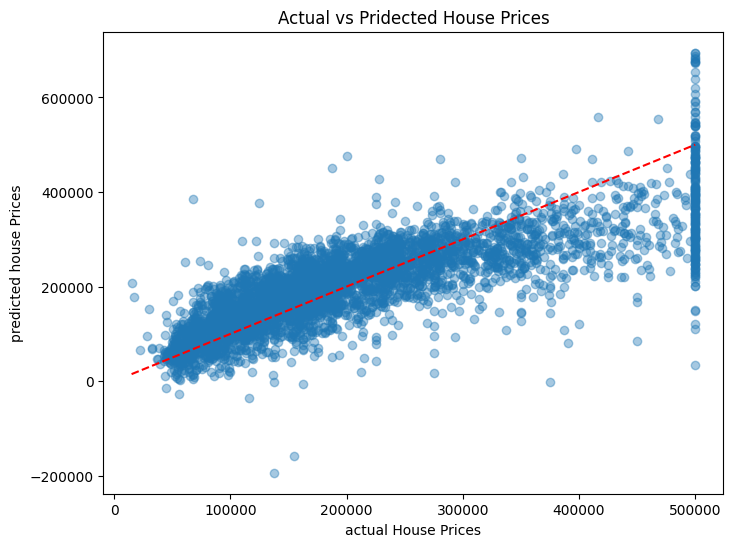

In [25]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,6))

plt.scatter(y_test, y_pred, alpha =0.4)

plt.xlabel("actual House Prices")
plt.ylabel("predicted house Prices")
plt.title("Actual vs Pridected House Prices")

# Perfect predictions reference line

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(),y_test.max()],
    "r--"
)

plt.show()

In [26]:
#check with manual data
# Manual input
new_house = pd.DataFrame({
    "longitude": [-122.23],
    "latitude": [37.88],
    "housing_median_age": [41],
    "total_rooms": [880],
    "total_bedrooms": [129],
    "population": [322],
    "households": [126],
    "median_income": [8.3252],
    "ocean_proximity": ["NEAR BAY"]
})

# Predict house value
prediction = model.predict(new_house)

print("Predicted House Value: $", round(prediction[0], 2))

Predicted House Value: $ 410584.36
